# Speed analysis of `thermal_PhaseCurve()`

The runtime is almost entirely the single SPIDERMAN `lightcurve(t)` call (~99% at defaults). Only two knobs matter:
- **`N_LAYERS`** — the SPIDERMAN radial resolution; scales roughly **quadratically**. By far the biggest lever.
- **`len(t)`** — number of time samples; scales **linearly**.

Everything that builds the temperature map (`n_lo`, `n_la`, `insolation_model`, penumbra `order`) is a <1% preamble, and `filter` / `include_transit` / `include_occultation` are within noise.

In [1]:
import time, os
import numpy as np
import matplotlib.pyplot as plt
import spiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import thermal_PhaseCurve, custom_temperature_grid, Louden_PhaseCurve
import kepler_utils, batman_utils
from kepler_utils import AU_to_RS

# --- K2-141b setup (same as test_ThermalPhaseCurve) ---
period, rp, rs, a_AU = 0.2803, 0.0204, 0.68, 0.007
a = AU_to_RS(a_AU, rs)
incl, ecc, w, T_eff = 86.3, 0., 90., 4570.
u = [0.1, 0.3]
A_B = 3/2 * 0.28
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

FILTER_DIR   = os.path.join(os.path.dirname(os.path.abspath('')), 'Filters', 'Spiderman')
lambda_range = 1e-6 * np.array([3.6955, 5.1008])                 # Spitzer/IRAC2
filter_path  = os.path.join(FILTER_DIR, "Spitzer_IRAC.I2.spiderman.dat")

def bench(fn, warmup=1, repeats=3):
    """Best-of-`repeats` wall time in milliseconds (warm-up excluded)."""
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1e3 * min(ts)

def time_tpc(**kw):
    """Time thermal_PhaseCurve with overrides on top of a kopal + filter baseline."""
    p = dict(u=u, A_B=A_B, filter_path=filter_path, insolation_model="kopal")
    p.update(kw)
    return bench(lambda: thermal_PhaseCurve(K2_141b, lambda_range, **p))

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


## 1. Where does the time go?  (stage decomposition)

The body of `thermal_PhaseCurve` is replicated below with a timer around each stage (defaults: kopal, filter, `N_LAYERS=60`, `n_lo=200`, `n_la=100`, `t=1000`).

no stellar models provided, using blackbody approximation


no stellar models provided, using blackbody approximation


total ~ 3100 ms

  MAIN lightcurve (SPIDERMAN, t=1000)                3071.1 ms  (99.08%)
  build temperature map (custom_temperature_grid)      13.1 ms  ( 0.42%)
  occultation depth (2x lightcurve @ 1 pt)             12.1 ms  ( 0.39%)
  stellar grid (gen_grid)                               2.7 ms  ( 0.09%)
  format_grid                                           0.7 ms  ( 0.02%)
  transit (batman)                                      0.0 ms  ( 0.00%)


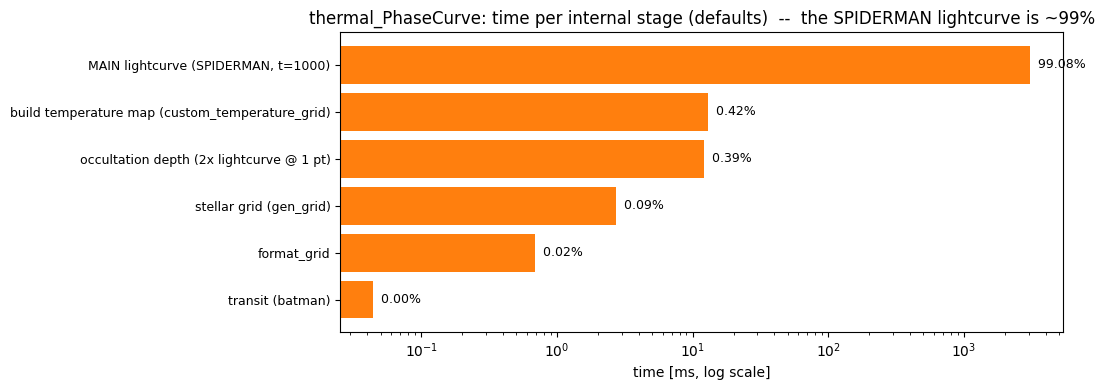

In [2]:
def decompose(n_lo=200, n_la=100, N_LAYERS=60, model="kopal", fpath=filter_path, ntime=1000):
    T = {}
    t0=time.perf_counter(); lo,la,tg = custom_temperature_grid(K2_141b, u=u, n_lo=n_lo, n_la=n_la, insolation_model=model, A_B=A_B); T["build temperature map (custom_temperature_grid)"]=time.perf_counter()-t0
    t0=time.perf_counter(); LO,LA=np.meshgrid(lo,la,indexing='ij'); grid=sp.format_grid(LO,LA,np.maximum(tg,100.).T); T["format_grid"]=time.perf_counter()-t0
    p=sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody"); p.n_layers=N_LAYERS
    p.t0,p.per=0.,period; p.a_abs=a_AU; p.inc,p.ecc,p.w=incl,ecc,w; p.rp,p.a=rp,a; p.p_u1=p.p_u2=0.
    p.T_s=T_eff; p.grid=grid; p.l1,p.l2=lambda_range; p.filter=fpath
    t0=time.perf_counter(); sg=sp.stellar_grid.gen_grid(p.l1,p.l2,logg=4.5,response=p.filter,stellar_model="blackbody"); T["stellar grid (gen_grid)"]=time.perf_counter()-t0
    tocc=kepler_utils.occultation_time(period,ecc,w,t0=0.)
    t0=time.perf_counter(); p.eclipse=False; p.lightcurve([tocc],stellar_grid=sg); p.eclipse=True; p.lightcurve([tocc],stellar_grid=sg); T["occultation depth (2x lightcurve @ 1 pt)"]=time.perf_counter()-t0
    tt=np.linspace(0.,period,ntime)
    t0=time.perf_counter(); p.lightcurve(tt,stellar_grid=sg); T["MAIN lightcurve (SPIDERMAN, t=%d)"%ntime]=time.perf_counter()-t0
    t0=time.perf_counter(); batman_utils.flux_transit(K2_141b,tt,t0=0.,u=u); T["transit (batman)"]=time.perf_counter()-t0
    return T

decompose()                       # warm-up
D = decompose()
tot = sum(D.values())
ks = sorted(D, key=lambda k: D[k])
print(f"total ~ {tot*1e3:.0f} ms\n")
for k in reversed(ks):
    print(f"  {k:48s} {D[k]*1e3:8.1f} ms  ({100*D[k]/tot:5.2f}%)")

fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(range(len(ks)), [D[k]*1e3 for k in ks], color="C1")
ax.set_yticks(range(len(ks))); ax.set_yticklabels(ks, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("time [ms, log scale]")
ax.set_title("thermal_PhaseCurve: time per internal stage (defaults)  --  the SPIDERMAN lightcurve is ~99%")
for i, k in enumerate(ks): ax.text(D[k]*1e3, i, f"  {100*D[k]/tot:.2f}%", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 2. `N_LAYERS` -- the dominant cost (≈ quadratic)

`N_LAYERS` sets SPIDERMAN's radial discretization of the planet disk (segments ~ `N_LAYERS`²), so it drives the one expensive call. Swept at a fixed modest `t=300` to isolate it.

  N_LAYERS=   5:     29.7 ms
  N_LAYERS=  10:     49.8 ms
  N_LAYERS=  20:    127.0 ms
  N_LAYERS=  30:    258.0 ms
  N_LAYERS=  45:    549.1 ms
  N_LAYERS=  60:    950.8 ms
  N_LAYERS=  90:   2097.1 ms
  N_LAYERS= 120:   3735.7 ms

power-law exponent (N_LAYERS>=20): 1.89   (2.0 = perfectly quadratic)


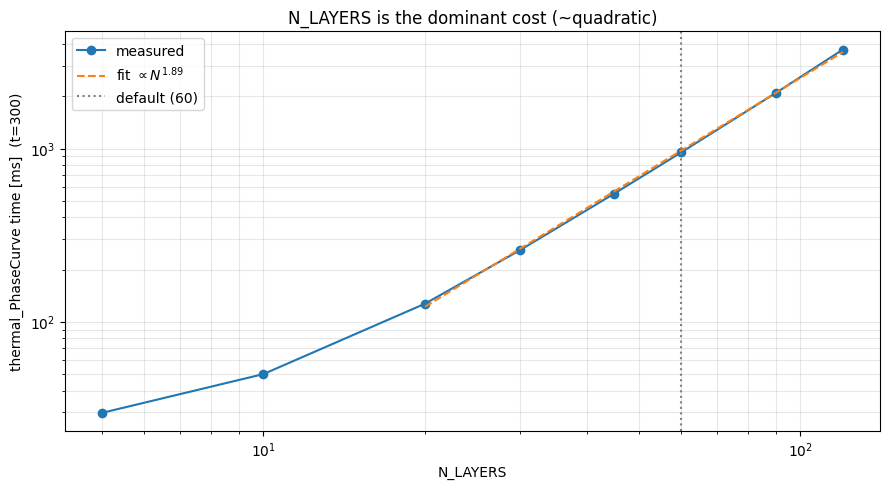

In [3]:
NL_vals = [5, 10, 20, 30, 45, 60, 90, 120]
t_grid  = np.linspace(0., period, 300)
NL_times = [time_tpc(N_LAYERS=nl, t=t_grid) for nl in NL_vals]
for nl, ms in zip(NL_vals, NL_times): print(f"  N_LAYERS={nl:4d}: {ms:8.1f} ms")

NLa = np.array(NL_vals, float); msa = np.array(NL_times); sel = NLa >= 20
slope, intc = np.polyfit(np.log(NLa[sel]), np.log(msa[sel]), 1)
print(f"\npower-law exponent (N_LAYERS>=20): {slope:.2f}   (2.0 = perfectly quadratic)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.loglog(NL_vals, NL_times, "o-", label="measured")
ax.loglog(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(60, color="grey", ls=":", label="default (60)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(NL_vals, NL_times, "o-", label="measured")
ax.plot(NLa[sel], np.exp(intc)*NLa[sel]**slope, "--", label=fr"fit $\propto N^{{{slope:.2f}}}$")
ax.axvline(60, color="grey", ls=":", label="default (60)")
ax.set_xlabel("N_LAYERS"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (t=300)")
ax.set_title("N_LAYERS is the dominant cost (~quadratic)"); ax.grid(which="both", alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 3. `len(t)` -- number of time samples (linear)

The lightcurve is evaluated point-by-point, so runtime is linear in `len(t)`. Swept at `N_LAYERS=30`.

  len(t)=  100:    102.3 ms
  len(t)=  300:    256.4 ms
  len(t)=  600:    485.7 ms
  len(t)= 1000:    794.7 ms
  len(t)= 2000:   1562.1 ms
  len(t)= 4000:   3091.4 ms


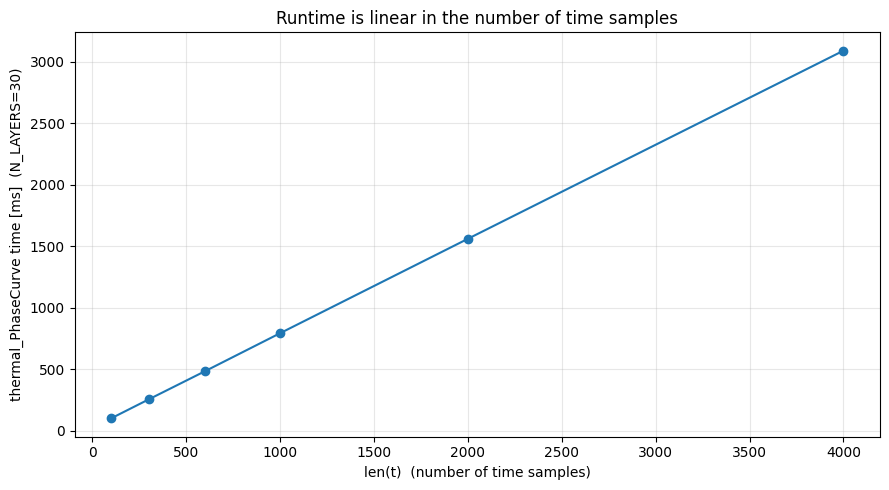

In [4]:
nt_vals  = [100, 300, 600, 1000, 2000, 4000]
nt_times = [time_tpc(N_LAYERS=30, t=np.linspace(0., period, n)) for n in nt_vals]
for n, ms in zip(nt_vals, nt_times): print(f"  len(t)={n:5d}: {ms:8.1f} ms")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(nt_vals, nt_times, "o-")
ax.set_xlabel("len(t)  (number of time samples)"); ax.set_ylabel("thermal_PhaseCurve time [ms]  (N_LAYERS=30)")
ax.set_title("Runtime is linear in the number of time samples"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Temperature-map parameters (`n_lo`, `n_la`, `insolation_model`, penumbra `order`)

These only affect the **map-building preamble** (`custom_temperature_grid`), which is <1% of a default call. Timed here in isolation to show their scaling.

- `n_lo` × `n_la`: linear in pixel count; the `kopal` model is ~30× more expensive than `naive` (it does the penumbra integral per pixel).
- penumbra `order`: the Gauss-Legendre order inside `insolation_penumbra_kopal` (linear). **Not exposed by `thermal_PhaseCurve`** — it is fixed at 32 internally, shown here only to size its contribution.

custom_temperature_grid (map build):
   100x 50 (  5000 px): kopal=   3.1 ms   naive=  0.23 ms
   200x100 ( 20000 px): kopal=  11.7 ms   naive=  0.47 ms
   400x200 ( 80000 px): kopal=  42.7 ms   naive=  1.31 ms
   800x400 (320000 px): kopal= 202.4 ms   naive=  5.73 ms

insolation_penumbra_kopal vs Gauss-Legendre order (6000 pts):
  order=   8:    1.9 ms
  order=  16:    3.1 ms
  order=  32:    5.5 ms
  order=  64:   10.9 ms
  order= 128:   22.8 ms


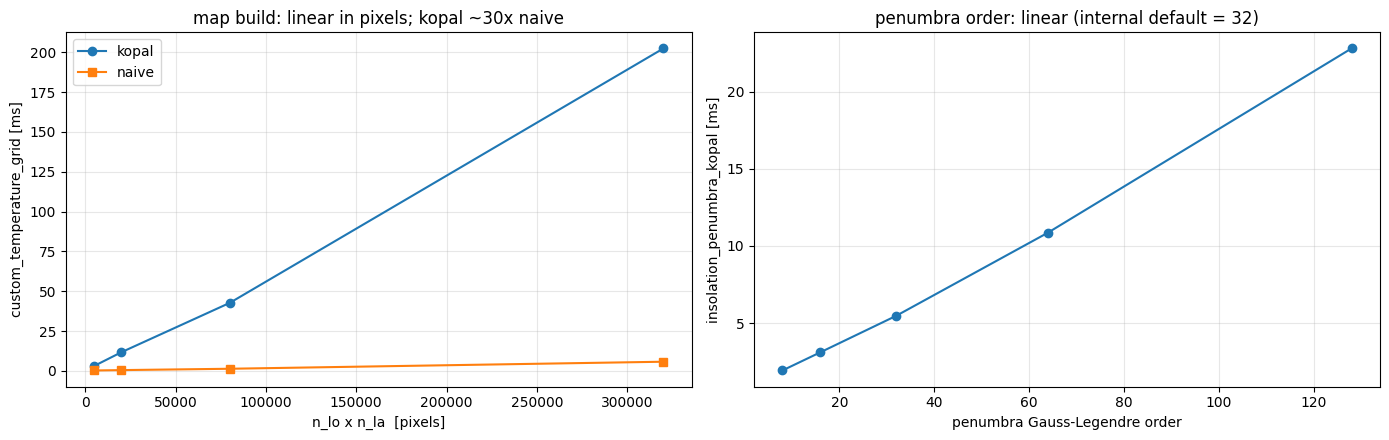


Context: at defaults the whole map build is ~12 ms out of ~3100 ms total (0.38%).


In [5]:
res  = [(100,50), (200,100), (400,200), (800,400)]
npix = [nlo*nla for nlo,nla in res]
tk = [bench(lambda nlo=nlo, nla=nla: custom_temperature_grid(K2_141b, n_lo=nlo, n_la=nla, insolation_model="kopal", A_B=A_B)) for nlo,nla in res]
tn = [bench(lambda nlo=nlo, nla=nla: custom_temperature_grid(K2_141b, n_lo=nlo, n_la=nla, insolation_model="naive", A_B=A_B)) for nlo,nla in res]
print("custom_temperature_grid (map build):")
for (nlo,nla), k, n in zip(res, tk, tn): print(f"  {nlo:4d}x{nla:3d} ({nlo*nla:6d} px): kopal={k:6.1f} ms   naive={n:6.2f} ms")

gp = np.linspace(K2_141b.terminator_penumbra(), K2_141b.terminator_nightside(), 6000)   # ~ #penumbra pixels in a 200x100 map
orders = [8, 16, 32, 64, 128]
to = [bench(lambda o=o: insolation_penumbra_kopal(gp, K2_141b, order=o)) for o in orders]
print("\ninsolation_penumbra_kopal vs Gauss-Legendre order (6000 pts):")
for o, ms in zip(orders, to): print(f"  order={o:4d}: {ms:6.1f} ms")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(npix, tk, "o-", label="kopal"); ax[0].plot(npix, tn, "s-", label="naive")
ax[0].set_xlabel("n_lo x n_la  [pixels]"); ax[0].set_ylabel("custom_temperature_grid [ms]")
ax[0].set_title("map build: linear in pixels; kopal ~30x naive"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot(orders, to, "o-"); ax[1].set_xlabel("penumbra Gauss-Legendre order"); ax[1].set_ylabel("insolation_penumbra_kopal [ms]")
ax[1].set_title("penumbra order: linear (internal default = 32)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"\nContext: at defaults the whole map build is ~{tk[1]:.0f} ms out of ~{sum(D.values())*1e3:.0f} ms total ({100*tk[1]/1e3/sum(D.values()):.2f}%).")

## 5. Factors with negligible impact

`filter` (SVO throughput vs tophat), `insolation_model`, `include_transit`, and `include_occultation` barely change the runtime — the SPIDERMAN call is the same size in all cases. Timed at `N_LAYERS=30`, `t=500`.

In [6]:
tt = np.linspace(0., period, 500)
rows = [
    ("filter: SVO throughput",      time_tpc(N_LAYERS=30, t=tt, filter_path=filter_path)),
    ("filter: none (tophat)",       time_tpc(N_LAYERS=30, t=tt, filter_path=False)),
    ("insolation_model: kopal",     time_tpc(N_LAYERS=30, t=tt, insolation_model="kopal")),
    ("insolation_model: naive",     time_tpc(N_LAYERS=30, t=tt, insolation_model="naive")),
    ("include_transit: True",       time_tpc(N_LAYERS=30, t=tt, include_transit=True)),
    ("include_transit: False",      time_tpc(N_LAYERS=30, t=tt, include_transit=False)),
    ("include_occultation: True",   time_tpc(N_LAYERS=30, t=tt, include_occultation=True)),
    ("include_occultation: False",  time_tpc(N_LAYERS=30, t=tt, include_occultation=False)),
]
for name, ms in rows: print(f"  {name:30s} {ms:7.1f} ms")

  filter: SVO throughput           408.9 ms
  filter: none (tophat)            403.0 ms
  insolation_model: kopal          409.5 ms
  insolation_model: naive          397.5 ms
  include_transit: True            414.3 ms
  include_transit: False           437.3 ms
  include_occultation: True        413.7 ms
  include_occultation: False       416.5 ms


## 6. Summary: impact ranking

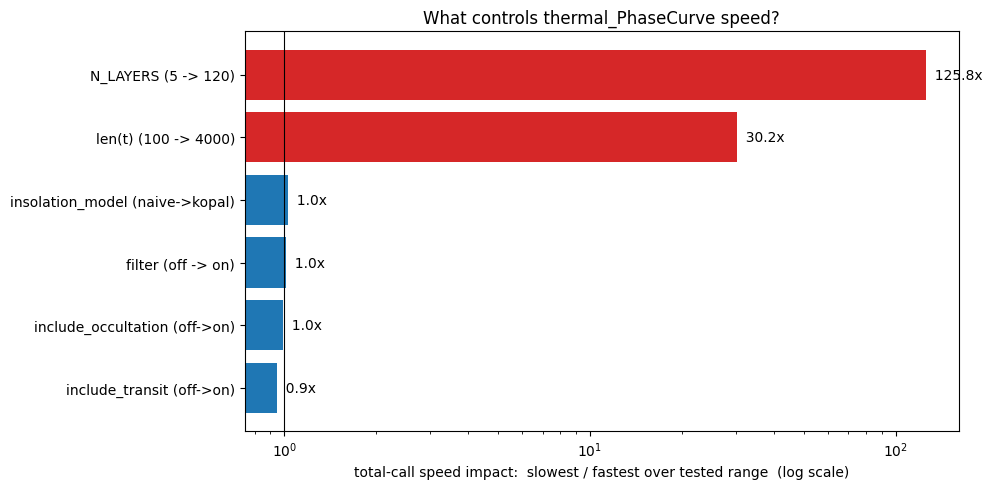

In [7]:
r = dict(rows)
impact = {
    "N_LAYERS (5 -> 120)":         max(NL_times)/min(NL_times),
    "len(t) (100 -> 4000)":        max(nt_times)/min(nt_times),
    "insolation_model (naive->kopal)": r["insolation_model: kopal"]/r["insolation_model: naive"],
    "filter (off -> on)":          r["filter: SVO throughput"]/r["filter: none (tophat)"],
    "include_transit (off->on)":   r["include_transit: True"]/r["include_transit: False"],
    "include_occultation (off->on)": r["include_occultation: True"]/r["include_occultation: False"],
}
ks = sorted(impact, key=lambda k: impact[k])
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["C3" if impact[k] > 3 else ("C1" if impact[k] > 1.3 else "C0") for k in ks]
ax.barh(range(len(ks)), [impact[k] for k in ks], color=colors)
ax.set_yticks(range(len(ks))); ax.set_yticklabels(ks)
ax.set_xscale("log"); ax.axvline(1, color="k", lw=.8)
ax.set_xlabel("total-call speed impact:  slowest / fastest over tested range  (log scale)")
ax.set_title("What controls thermal_PhaseCurve speed?")
for i, k in enumerate(ks): ax.text(impact[k], i, f"  {impact[k]:.1f}x", va="center")
plt.tight_layout(); plt.show()

## 7. Convergence with N_LAYERS

Here each illumination model's phase curve is compared against a high-resolution **ground truth** (`N_LAYERS = 240`) computed on the *same* time grid, so the curves differ only through `N_LAYERS`. The convergence metric is the **RMS deviation of the phase curve from the ground truth (ppm)**; the maximum pointwise deviation and the occultation-depth error $|f_p - f_p^{\rm GT}|$ are shown alongside.

ground truth: N_LAYERS = 240   (f_p [ppm]: naive = 148.18, kopal = 149.36, louden = 148.18)

  naive : RMS deviation ~ N_LAYERS^-1.62   (RMS ~ 0.025 ppm at default N=60)
  kopal : RMS deviation ~ N_LAYERS^-1.60   (RMS ~ 0.026 ppm at default N=60)
  louden: RMS deviation ~ N_LAYERS^-1.62   (RMS ~ 0.025 ppm at default N=60)


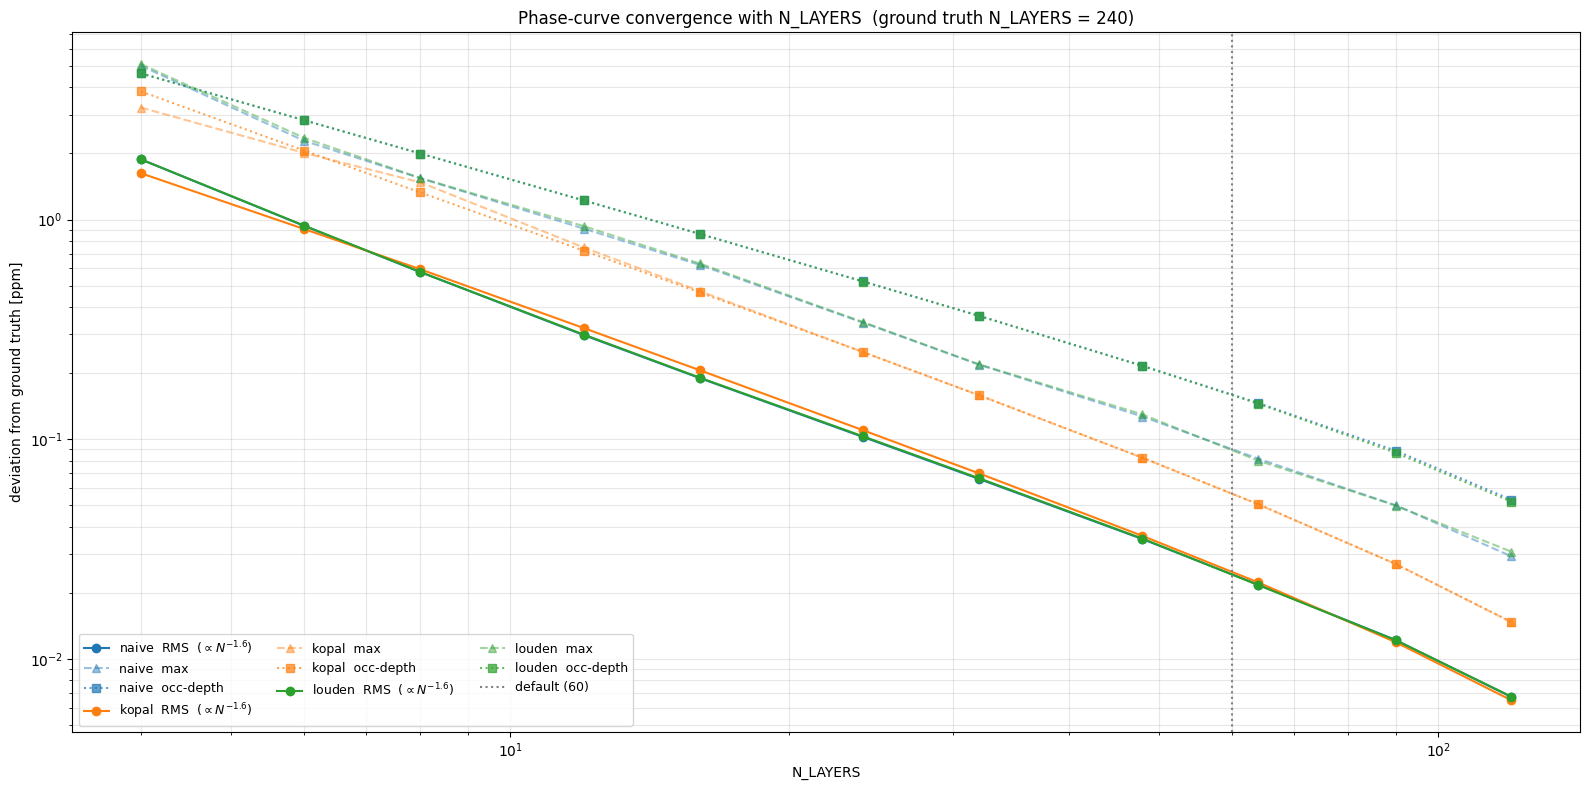

In [8]:
# Convergence of the phase curve with N_LAYERS, vs a high-N_LAYERS ground truth, for all three models
t_conv  = np.linspace(0., period, 200)               # shared grid -> curves differ only through N_LAYERS
NL_GT   = 240                                        # ground-truth reference resolution
NL_conv = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 90, 120])

def _phasecurve(model, nl):
    if model == "louden":   # separate SPIDERMAN model (analytic F=0 map); u left at its default
        return Louden_PhaseCurve(K2_141b, lambda_range, t=t_conv, A_B=A_B, filter_path=filter_path, N_LAYERS=nl)
    return thermal_PhaseCurve(K2_141b, lambda_range, t=t_conv, u=u, A_B=A_B, filter_path=filter_path,
                              insolation_model=model, N_LAYERS=nl)

conv = {}
for model in ["naive", "kopal", "louden"]:
    _, pc_gt, fp_gt, _ = _phasecurve(model, NL_GT)
    rms, mx, fperr = [], [], []
    for nl in NL_conv:
        _, pc, fp, _ = _phasecurve(model, int(nl))
        d = (pc - pc_gt) * 1e6                        # pointwise deviation [ppm]
        rms.append(np.sqrt(np.mean(d**2))); mx.append(np.abs(d).max()); fperr.append(abs(fp - fp_gt))
    conv[model] = dict(rms=np.array(rms), mx=np.array(mx), fperr=np.array(fperr), fp_gt=fp_gt)

print(f"ground truth: N_LAYERS = {NL_GT}   (f_p [ppm]: " + ", ".join(f"{m} = {conv[m]['fp_gt']:.2f}" for m in conv) + ")\n")
rate = {}
for model in ["naive", "kopal", "louden"]:
    slope, _ = np.polyfit(np.log(NL_conv), np.log(conv[model]["rms"]), 1)
    rate[model] = -slope
    i60 = np.interp(60, NL_conv, conv[model]["rms"])
    print(f"  {model:6s}: RMS deviation ~ N_LAYERS^-{-slope:.2f}   (RMS ~ {i60:.3f} ppm at default N=60)")

plt.figure(figsize=(16, 8))
for model, c in [("naive", "C0"), ("kopal", "C1"), ("louden", "C2")]:
    plt.loglog(NL_conv, conv[model]["rms"],   "o-",  color=c, label=fr"{model}  RMS  ($\propto N^{{-{rate[model]:.1f}}}$)")
    plt.loglog(NL_conv, conv[model]["mx"],    "^--", color=c, alpha=.45, label=f"{model}  max")
    plt.loglog(NL_conv, conv[model]["fperr"], "s:",  color=c, alpha=.7,  label=f"{model}  occ-depth")
plt.axvline(60, color="grey", ls=":", label="default (60)")
plt.xlabel("N_LAYERS"); plt.ylabel("deviation from ground truth [ppm]")
plt.title(f"Phase-curve convergence with N_LAYERS  (ground truth N_LAYERS = {NL_GT})")
plt.grid(which="both", alpha=.3); plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

## 8. Runtime: `Louden_PhaseCurve` vs `thermal_PhaseCurve(naive)`

  N_LAYERS=   4: thermal(naive) =     15.2 ms   Louden =     14.4 ms   speedup = 1.06x
  N_LAYERS=   8: thermal(naive) =     27.7 ms   Louden =     15.2 ms   speedup = 1.82x
  N_LAYERS=  16: thermal(naive) =     82.6 ms   Louden =     24.4 ms   speedup = 3.39x
  N_LAYERS=  30: thermal(naive) =    243.4 ms   Louden =     55.0 ms   speedup = 4.42x
  N_LAYERS=  45: thermal(naive) =    544.6 ms   Louden =    112.6 ms   speedup = 4.84x
  N_LAYERS=  60: thermal(naive) =    937.1 ms   Louden =    188.3 ms   speedup = 4.98x
  N_LAYERS=  90: thermal(naive) =   2082.0 ms   Louden =    392.8 ms   speedup = 5.30x
  N_LAYERS= 120: thermal(naive) =   3729.1 ms   Louden =    653.9 ms   speedup = 5.70x


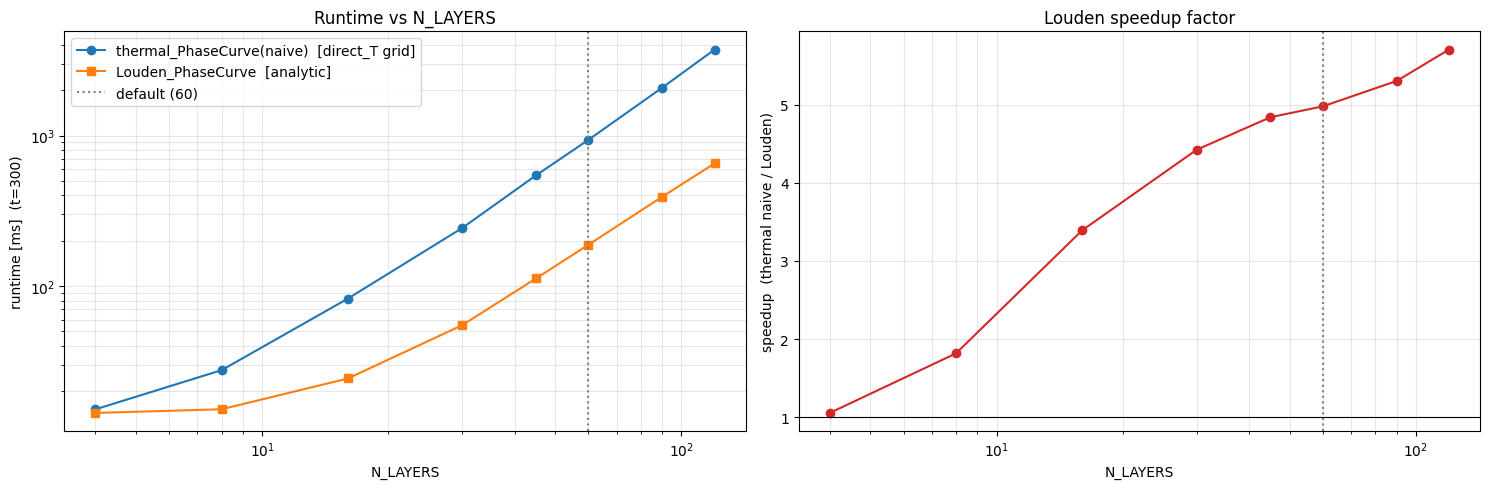

In [9]:
NL_rt = [4, 8, 16, 30, 45, 60, 90, 120]
t_rt  = np.linspace(0., period, 300)
rt_naive  = [bench(lambda nl: thermal_PhaseCurve(K2_141b, lambda_range, t=t_rt, u=u, A_B=A_B,
                    filter_path=filter_path, insolation_model="naive", N_LAYERS=nl), repeats=2) for nl in NL_rt]
rt_louden = [bench(lambda nl: Louden_PhaseCurve(K2_141b, lambda_range, t=t_rt, A_B=A_B,
                    filter_path=filter_path, N_LAYERS=nl), repeats=2) for nl in NL_rt]
for nl, n, l in zip(NL_rt, rt_naive, rt_louden):
    print(f"  N_LAYERS={nl:4d}: thermal(naive) = {n:8.1f} ms   Louden = {l:8.1f} ms   speedup = {n/l:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].loglog(NL_rt, rt_naive,  "o-", label="thermal_PhaseCurve(naive)  [direct_T grid]")
ax[0].loglog(NL_rt, rt_louden, "s-", label="Louden_PhaseCurve  [analytic]")
ax[0].axvline(60, color="grey", ls=":", label="default (60)")
ax[0].set_xlabel("N_LAYERS"); ax[0].set_ylabel("runtime [ms]  (t=300)")
ax[0].set_title("Runtime vs N_LAYERS"); ax[0].grid(which="both", alpha=.3); ax[0].legend()
ax[1].semilogx(NL_rt, np.array(rt_naive)/np.array(rt_louden), "o-", color="C3")
ax[1].axhline(1, color="k", lw=.8); ax[1].axvline(60, color="grey", ls=":")
ax[1].set_xlabel("N_LAYERS"); ax[1].set_ylabel("speedup  (thermal naive / Louden)")
ax[1].set_title("Louden speedup factor"); ax[1].grid(which="both", alpha=.3)
plt.tight_layout(); plt.show()